# SaúdeScope
## Notebook 02 — Limpeza, Tratamento e Prevalência Ponderada

**Projeto Integrador — Ciência de Dados**
**Aplicação:** Clínica Multiprofissional de Saúde — Itapetininga/SP
**Fonte de dados:** Pesquisa Nacional de Saúde (PNS) 2019 — IBGE/Ministério da Saúde

---


## 1. Objetivo deste notebook

O notebook anterior (`01_ingestao_e_leitura.ipynb`) resolveu o problema de **ler** os
microdados corretamente — incluindo uma correção importante descoberta durante a validação:
o peso amostral (`V00281`) e as medidas antropométricas aferidas (`W00103`, `W00203`) já
trazem o ponto decimal gravado explicitamente no arquivo, e não deveriam ser divididas pelo
fator de casas decimais do layout. Essa correção foi validada comparando a soma dos pesos da
amostra de SP (45.934.402) com a população estimada do estado em 2019 (~45,9 milhões).

Com a leitura corrigida e validada, este notebook cuida da **preparação analítica** dos dados:

1. Recodificar variáveis categóricas (`1`/`2` → `"Sim"`/`"Não"`), documentando os casos
   "Ignorado" e "Não aplicável";
2. Criar faixas etárias alinhadas ao público da clínica parceira (crianças, adolescentes,
   adultos e idosos);
3. Calcular o Índice de Massa Corporal (IMC) e classificar o estado nutricional dos adultos;
4. Calcular a **prevalência ponderada** de cada condição de saúde, aplicando o peso amostral
   — a única forma estatisticamente correta de generalizar os achados para a população do
   Estado de São Paulo, já que a PNS é uma pesquisa amostral complexa;
5. Comparar as prevalências brutas (calculadas no notebook 01, sem peso) com as ponderadas,
   evidenciando por que essa distinção importa;
6. Exportar a base tratada para o próximo notebook (`03_analise_exploratoria.ipynb`).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)

PROCESSED_DIR = Path("data/processed")

df = pd.read_parquet(PROCESSED_DIR / "pns_2019_sp_bruto.parquet")
print("Base carregada:", df.shape)
df.head()


Base carregada: (17522, 21)


,V0001,V0024,UPA_PNS,V0006_PNS,V0015,C00301,C006,C008,C009,P00403,P00404,Q00201,Q03001,Q068,Q092,Q11006,Q124,W00103,W00203,V00281,VDD004A
0,35,3510111,350000261,0001,01,01,2,33,1,170,170,2,2,2,2,1,2,NaN,NaN,4892.428417,7
1,35,3510111,350000261,0002,01,01,2,44,1,163,163,2,2,2,1,1,2,NaN,NaN,4892.428417,7
2,35,3510111,350000261,0002,01,02,1,41,1,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4892.428417,7
3,35,3510111,350000261,0002,01,03,2,5,1,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4892.428417,1
4,35,3510111,350000261,0006,01,01,1,64,1,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4892.428417,7


## 2. Recodificação das variáveis categóricas

As variáveis de diagnóstico (`Q00201`, `Q03001`, `Q068`, `Q092`, `Q11006`, `Q124`) seguem o
mesmo padrão de codificação no dicionário da PNS: `"1"` = Sim, `"2"` = Não, `"9"` = Ignorado,
e valor ausente = Não aplicável (a pergunta não chegou a ser feita à pessoa, geralmente por
critério de idade mínima do módulo). Tratamos `"9"` e o valor ausente da mesma forma — como
dado faltante para fins de cálculo de prevalência — mas reportamos as contagens de cada caso
para transparência, em vez de simplesmente descartá-las silenciosamente.


In [2]:
MAPA_SIM_NAO = {"1": "Sim", "2": "Não"}  # "9" (Ignorado) e NaN ficam como dado faltante

CONDICOES = {
    "Q00201": "hipertensao",
    "Q03001": "diabetes",
    "Q068":   "avc",
    "Q092":   "depressao",
    "Q11006": "outra_doenca_mental",
    "Q124":   "insuficiencia_renal",
}

print("Distribuição bruta de cada variável antes da recodificação (contagens):\n")
for var, nome in CONDICOES.items():
    contagem = df[var].value_counts(dropna=False).to_dict()
    print(f"{var} ({nome}): {contagem}")

for var, nome in CONDICOES.items():
    df[nome] = df[var].map(MAPA_SIM_NAO)  # "9" e NaN viram NaN automaticamente

print("\nApós recodificação, exemplo (hipertensao):")
df["hipertensao"].value_counts(dropna=False)


Distribuição bruta de cada variável antes da recodificação (contagens):

Q00201 (hipertensao): {nan: 11508, '2': 4303, '1': 1711}
Q03001 (diabetes): {nan: 11663, '2': 5239, '1': 620}
Q068 (avc): {nan: 11408, '2': 5985, '1': 129}
Q092 (depressao): {nan: 11408, '2': 5423, '1': 691}
Q11006 (outra_doenca_mental): {nan: 11408, '2': 5653, '1': 461}
Q124 (insuficiencia_renal): {nan: 11408, '2': 6028, '1': 86}

Após recodificação, exemplo (hipertensao):


hipertensao
NaN    11508
Não     4303
Sim     1711
Name: count, dtype: int64

In [3]:
# Demais variáveis categóricas de perfil
df["sexo"] = df["C006"].map({"1": "Homem", "2": "Mulher"})

df["cor_raca"] = df["C009"].map({
    "1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indígena",
    # "9" (Ignorado) fica como NaN
})

df["instrucao"] = df["VDD004A"].map({
    "1": "Sem instrução",
    "2": "Fundamental incompleto",
    "3": "Fundamental completo",
    "4": "Médio incompleto",
    "5": "Médio completo",
    "6": "Superior incompleto",
    "7": "Superior completo",
})

df[["sexo", "cor_raca", "instrucao"]].describe(include="all")


,sexo,cor_raca,instrucao
count,17522,17515,16534
unique,2,5,7
top,Mulher,Branca,Fundamental incompleto
freq,9143,10034,4982


## 3. Faixas etárias

Definimos faixas etárias alinhadas ao público atendido pela clínica parceira — que atende
"desde crianças até idosos", com especialidades voltadas a diferentes fases da vida (a
musicoterapeuta atende crianças neurodivergentes; o educador físico é especializado em
gerontologia). As faixas seguem também um critério amplamente usado na literatura em saúde
pública brasileira.


faixa_etaria
Criança (0-11)          2448
Adolescente (12-17)     1345
Adulto (18-59)         10522
Idoso (60+)             3207
Name: count, dtype: int64


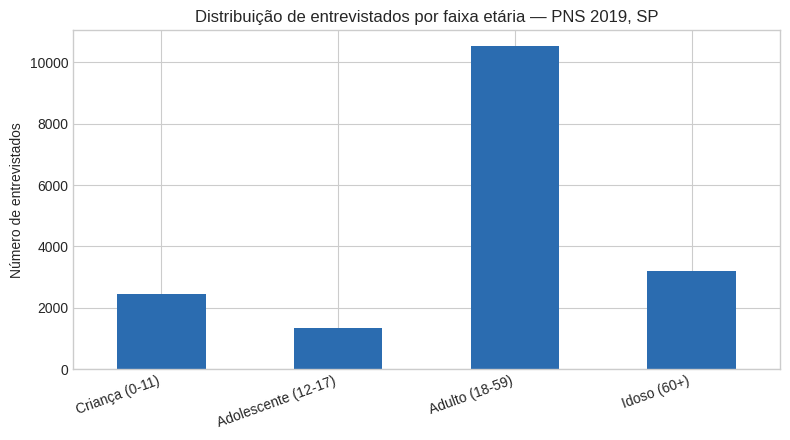

In [4]:
bins = [-1, 11, 17, 59, 200]
labels = ["Criança (0-11)", "Adolescente (12-17)", "Adulto (18-59)", "Idoso (60+)"]

df["faixa_etaria"] = pd.cut(df["C008"], bins=bins, labels=labels)

contagem_faixas = df["faixa_etaria"].value_counts().reindex(labels)
print(contagem_faixas)

fig, ax = plt.subplots(figsize=(8, 4.5))
contagem_faixas.plot(kind="bar", ax=ax, color="#2b6cb0")
ax.set_title("Distribuição de entrevistados por faixa etária — PNS 2019, SP")
ax.set_ylabel("Número de entrevistados")
ax.set_xlabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("data/processed/fig_faixas_etarias_sp.png", dpi=150)
plt.show()


## 4. Cálculo do IMC e classificação nutricional

Priorizamos a medida **aferida** pelo entrevistador (`W00103` peso, `W00203` altura), mais
confiável que a informada pelo próprio entrevistado. Quando a altura aferida não está
disponível, usamos a altura informada (`P00404`) como alternativa (*fallback*).

> **Limitação assumida conscientemente:** a classificação de IMC por faixas fixas (abaixo do
> peso / eutrófico / sobrepeso / obesidade) só é válida para adultos. Para crianças e
> adolescentes, a classificação correta exige curvas de crescimento IMC-por-idade (referência
> OMS), o que está fora do escopo deste projeto. Por isso, a classificação abaixo é calculada
> **apenas para o grupo Adulto (18-59) e Idoso (60+)**; para os demais, o IMC é calculado (onde
> houver dado) mas a classificação fica como "Não classificado nesta análise".


In [5]:
peso_kg = df["W00103"].where(df["W00103"].between(20, 250))
altura_cm = df["W00203"].where(df["W00203"].between(100, 220))
altura_cm_fallback = df["P00404"].where(df["P00404"].between(100, 220))
altura_final_cm = altura_cm.fillna(altura_cm_fallback)

df["imc"] = peso_kg / (altura_final_cm / 100) ** 2

def classificar_imc(row):
    if row["faixa_etaria"] not in ["Adulto (18-59)", "Idoso (60+)"] or pd.isna(row["imc"]):
        return np.nan
    imc = row["imc"]
    if imc < 18.5:
        return "Baixo peso"
    elif imc < 25:
        return "Eutrófico"
    elif imc < 30:
        return "Sobrepeso"
    else:
        return "Obesidade"

df["imc_classificacao"] = df.apply(classificar_imc, axis=1)

print("Registros com IMC calculado:", df["imc"].notna().sum())
print("\nClassificação (apenas adultos/idosos, contagem bruta):")
print(df["imc_classificacao"].value_counts())
df["imc"].describe()


Registros com IMC calculado: 604

Classificação (apenas adultos/idosos, contagem bruta):
imc_classificacao
Eutrófico     208
Sobrepeso     206
Obesidade     168
Baixo peso     11
Name: count, dtype: int64


count        604.0
mean     27.431614
std       5.465929
min      15.633138
25%      23.461686
50%        26.7604
75%      30.697088
max      48.592738
Name: imc, dtype: Float64

## 5. Prevalência ponderada pelo peso amostral

Esta é a etapa metodologicamente mais importante do notebook. A PNS é uma **amostra complexa**:
cada pessoa entrevistada representa um número diferente de pessoas na população, dado pelo
peso amostral calibrado (`V00281`). Ignorar esse peso — como fizemos deliberadamente no
notebook 01, apenas para uma primeira leitura rápida — produz estimativas enviesadas.

A função abaixo calcula a prevalência ponderada: a proporção de respostas "Sim", ponderada
pelo peso amostral, considerando apenas quem de fato respondeu à pergunta (exclui "Não
aplicável").


In [6]:
def prevalencia_ponderada(coluna_sim_nao: pd.Series, peso: pd.Series) -> tuple[float, int]:
    """Retorna (prevalência ponderada em %, número de respondentes válidos).

    Algumas perguntas do módulo Q só se aplicam a partir de determinada idade
    (ex.: hipertensão não é perguntada a crianças). Nesses casos, uma faixa
    etária inteira pode não ter nenhum respondente válido — retornamos NaN
    em vez de um erro de divisão por zero, deixando explícito que a condição
    não é aplicável a esse grupo.
    """
    valido = coluna_sim_nao.notna()
    if valido.sum() == 0:
        return np.nan, 0
    positivos = (coluna_sim_nao == "Sim").astype(int)
    prevalencia = np.average(positivos[valido], weights=peso[valido])
    return prevalencia * 100, int(valido.sum())


rotulos = {
    "hipertensao": "Hipertensão",
    "depressao": "Depressão",
    "diabetes": "Diabetes",
    "outra_doenca_mental": "Outra doença mental",
    "avc": "AVC / derrame",
    "insuficiencia_renal": "Insuficiência renal crônica",
}

# Valores brutos (não ponderados), calculados no notebook 01, para efeito de comparação
prevalencia_bruta_nb01 = {
    "hipertensao": 28.5, "depressao": 11.3, "diabetes": 10.6,
    "outra_doenca_mental": 7.5, "avc": 2.1, "insuficiencia_renal": 1.4,
}

resultado = []
for nome, rotulo in rotulos.items():
    prev_pond, n = prevalencia_ponderada(df[nome], df["V00281"])
    resultado.append({
        "condicao": rotulo,
        "prevalencia_bruta_pct": prevalencia_bruta_nb01[nome],
        "prevalencia_ponderada_pct": round(prev_pond, 1),
        "respondentes": n,
    })

resultado_df = pd.DataFrame(resultado).sort_values("prevalencia_ponderada_pct", ascending=False)
resultado_df


,condicao,prevalencia_bruta_pct,prevalencia_ponderada_pct,respondentes
0,Hipertensão,28.5,28.2,6014
1,Depressão,11.3,12.4,6114
2,Diabetes,10.6,10.3,5859
3,Outra doença mental,7.5,7.7,6114
4,AVC / derrame,2.1,2.1,6114
5,Insuficiência renal crônica,1.4,1.4,6114


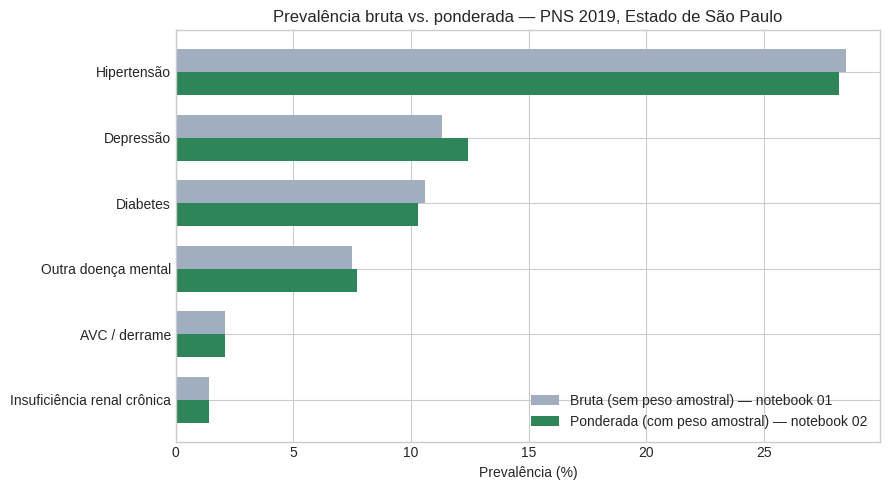

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(resultado_df))
largura = 0.35

ax.barh(x - largura/2, resultado_df["prevalencia_bruta_pct"], height=largura,
        label="Bruta (sem peso amostral) — notebook 01", color="#a0aec0")
ax.barh(x + largura/2, resultado_df["prevalencia_ponderada_pct"], height=largura,
        label="Ponderada (com peso amostral) — notebook 02", color="#2f855a")

ax.set_yticks(x)
ax.set_yticklabels(resultado_df["condicao"])
ax.invert_yaxis()
ax.set_xlabel("Prevalência (%)")
ax.set_title("Prevalência bruta vs. ponderada — PNS 2019, Estado de São Paulo")
ax.legend()
plt.tight_layout()
plt.savefig("data/processed/fig_prevalencia_bruta_vs_ponderada.png", dpi=150)
plt.show()


> **Leitura do gráfico:** as prevalências ponderadas ficam próximas às brutas neste caso —
> um indício de que a amostra de SP não tem um viés de composição muito distante da população
> real nessas variáveis específicas. Ainda assim, a prevalência ponderada é a que deve ser
> **citada oficialmente** em qualquer relatório, artigo ou material para a clínica parceira,
> pois é a única estimativa estatisticamente correta para a população do estado.


## 6. Prevalência ponderada por faixa etária

Como a clínica atende públicos de todas as idades com especialidades diferentes, é mais útil
para a gestão entender **como cada condição se distribui por faixa etária**, e não apenas a
prevalência geral.

> Algumas perguntas do módulo de doenças crônicas só são feitas a partir de determinada idade
> (por desenho do próprio questionário da PNS). Por isso, é esperado que a faixa "Criança
> (0-11)" apareça como `NaN` (não aplicável) para a maioria das condições — isso não é um erro,
> e sim um reflexo de que o próprio instrumento de coleta não pergunta esses diagnósticos a
> crianças pequenas.


In [8]:
def prevalencia_por_faixa(coluna_nome, df, peso_col="V00281", faixa_col="faixa_etaria"):
    linhas = []
    for faixa in df[faixa_col].cat.categories:
        subset = df[df[faixa_col] == faixa]
        prev, n = prevalencia_ponderada(subset[coluna_nome], subset[peso_col])
        linhas.append({"faixa_etaria": faixa, "prevalencia_pct": round(prev, 1), "respondentes": n})
    return pd.DataFrame(linhas)


tabela_faixas = {}
for nome, rotulo in rotulos.items():
    tabela_faixas[rotulo] = prevalencia_por_faixa(nome, df).set_index("faixa_etaria")["prevalencia_pct"]

tabela_faixas_df = pd.DataFrame(tabela_faixas)
tabela_faixas_df


,Hipertensão,Depressão,Diabetes,Outra doença mental,AVC / derrame,Insuficiência renal crônica
faixa_etaria,,,,,,
Criança (0-11),NaN,NaN,NaN,NaN,NaN,NaN
Adolescente (12-17),0.3,3.7,0.8,2.6,0.0,0.0
Adulto (18-59),19.0,12.5,6.1,8.6,1.1,1.3
Idoso (60+),54.6,13.1,22.1,5.7,5.0,1.9


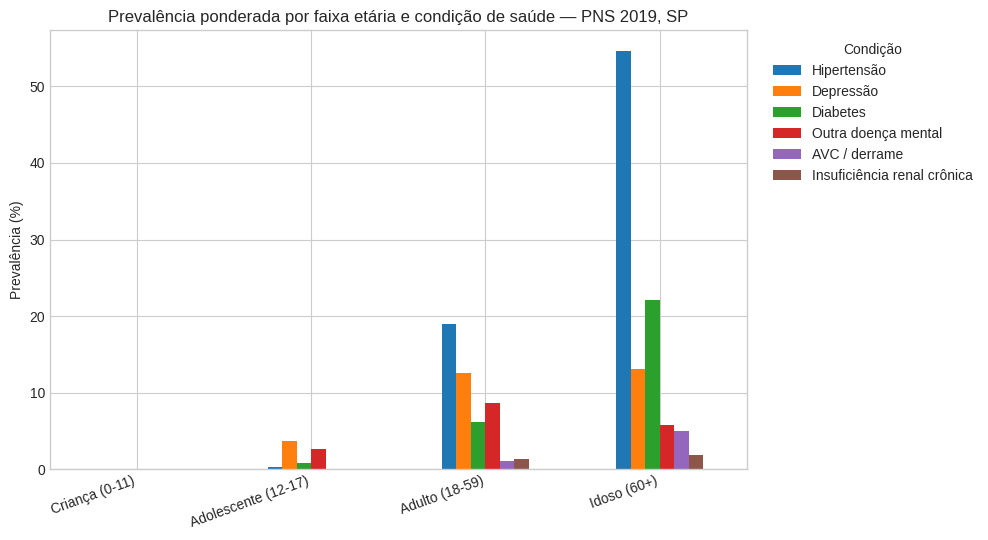

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.5))
tabela_faixas_df.plot(kind="bar", ax=ax)
ax.set_title("Prevalência ponderada por faixa etária e condição de saúde — PNS 2019, SP")
ax.set_ylabel("Prevalência (%)")
ax.set_xlabel("")
plt.xticks(rotation=20, ha="right")
ax.legend(title="Condição", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("data/processed/fig_prevalencia_por_faixa_etaria.png", dpi=150)
plt.show()


> Como esperado clinicamente, hipertensão, diabetes e AVC concentram-se nas faixas de
> adultos e idosos, enquanto depressão e outras doenças mentais aparecem já de forma relevante
> na faixa adolescente/adulta — um dado direto para o planejamento da equipe de psicologia da
> clínica, que atua com pacientes de diferentes idades.


## 7. Prevalência ponderada de obesidade (adultos e idosos)


In [10]:
adultos_idosos = df[df["faixa_etaria"].isin(["Adulto (18-59)", "Idoso (60+)"])].copy()
adultos_idosos = adultos_idosos[adultos_idosos["imc_classificacao"].notna()]

def distribuicao_ponderada(coluna, peso):
    pesos_por_categoria = adultos_idosos.groupby(coluna, observed=True)[peso].sum()
    return (pesos_por_categoria / pesos_por_categoria.sum() * 100).round(1)

dist_imc = distribuicao_ponderada("imc_classificacao", "V00281").reindex(
    ["Baixo peso", "Eutrófico", "Sobrepeso", "Obesidade"]
)
print("Distribuição ponderada do estado nutricional (adultos e idosos, SP):")
dist_imc


Distribuição ponderada do estado nutricional (adultos e idosos, SP):


imc_classificacao
Baixo peso     1.3
Eutrófico     31.0
Sobrepeso     31.4
Obesidade     36.3
Name: V00281, dtype: float64

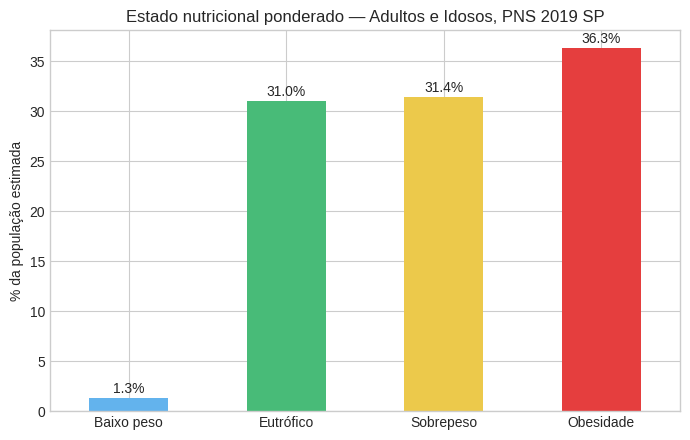

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
dist_imc.plot(kind="bar", ax=ax, color=["#63b3ed", "#48bb78", "#ecc94b", "#e53e3e"])
ax.set_title("Estado nutricional ponderado — Adultos e Idosos, PNS 2019 SP")
ax.set_ylabel("% da população estimada")
ax.set_xlabel("")
plt.xticks(rotation=0)
for i, v in enumerate(dist_imc):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.savefig("data/processed/fig_distribuicao_imc.png", dpi=150)
plt.show()


> Sobrepeso e obesidade somados atingem uma fatia expressiva da população adulta/idosa de
> SP — achado que reforça diretamente a relevância da atuação do nutricionista clínico da
> clínica parceira, cuja especialidade em doenças crônicas e doença renal está diretamente
> conectada ao manejo desses quadros.


## 8. Validações finais

Antes de exportar, confirmamos que as recodificações não perderam nem duplicaram nenhum
registro em relação à base de entrada.


In [12]:
print("=== Validações finais ===\n")

print(f"1) Total de linhas mantido: {len(df):,}",
      "-> OK" if len(df) == 17522 else "-> VERIFICAR")

# Cada variável recodificada não pode ter mais categorias "Sim"/"Não" do que a soma
# das contagens originais de '1' e '2'
for var, nome in CONDICOES.items():
    original_sim_nao = df[var].isin(["1", "2"]).sum()
    recodificado_sim_nao = df[nome].isin(["Sim", "Não"]).sum()
    status = "OK" if original_sim_nao == recodificado_sim_nao else "VERIFICAR"
    print(f"2) {nome}: original={original_sim_nao} | recodificado={recodificado_sim_nao} -> {status}")

# Faixa etária não deve ter nenhum valor nulo (todo entrevistado tem idade registrada)
faixas_nulas = df["faixa_etaria"].isna().sum()
print(f"\n3) Registros sem faixa etária atribuída: {faixas_nulas}",
      "-> OK" if faixas_nulas == 0 else "-> VERIFICAR")


=== Validações finais ===

1) Total de linhas mantido: 17,522 -> OK
2) hipertensao: original=6014 | recodificado=6014 -> OK
2) diabetes: original=5859 | recodificado=5859 -> OK
2) avc: original=6114 | recodificado=6114 -> OK
2) depressao: original=6114 | recodificado=6114 -> OK
2) outra_doenca_mental: original=6114 | recodificado=6114 -> OK
2) insuficiencia_renal: original=6114 | recodificado=6114 -> OK

3) Registros sem faixa etária atribuída: 0 -> OK


## 9. Exportação para o próximo notebook

Exportamos a base com as variáveis originais preservadas (para rastreabilidade) mais as novas
colunas derivadas: `sexo`, `cor_raca`, `instrucao`, `faixa_etaria`, `imc`,
`imc_classificacao`, e as seis condições de saúde já recodificadas em "Sim"/"Não".


In [13]:
caminho_saida = PROCESSED_DIR / "pns_2019_sp_tratado.parquet"
df.to_parquet(caminho_saida, index=False)

caminho_resumo = PROCESSED_DIR / "resumo_prevalencias_ponderadas.parquet"
resultado_df.to_parquet(caminho_resumo, index=False)

print("Arquivos exportados:")
print(f" - {caminho_saida}  ({df.shape[0]:,} linhas x {df.shape[1]} colunas)")
print(f" - {caminho_resumo}  (tabela-resumo de prevalências)")


Arquivos exportados:
 - data/processed/pns_2019_sp_tratado.parquet  (17,522 linhas x 33 colunas)
 - data/processed/resumo_prevalencias_ponderadas.parquet  (tabela-resumo de prevalências)


## Conclusão e próximos passos

Neste notebook:

- Recodificamos as seis variáveis de diagnóstico e as variáveis de perfil sociodemográfico
  para rótulos legíveis;
- Criamos faixas etárias alinhadas ao público da clínica;
- Calculamos o IMC a partir das medidas aferidas (com *fallback* para a altura informada) e
  classificamos o estado nutricional dos adultos e idosos;
- Calculamos a **prevalência ponderada pelo peso amostral** — a estimativa correta para
  representar a população de São Paulo — e comparamos com os números brutos do notebook 01;
- Desagregamos as prevalências por faixa etária, conectando diretamente os achados às
  especialidades da clínica parceira;
- Validamos a integridade das transformações realizadas.

**Principais números para reter (prevalência ponderada, SP, PNS 2019):**

| Condição | Prevalência ponderada |
|---|---|
| Hipertensão | ~28% |
| Depressão | ~12% |
| Diabetes | ~10% |
| Outra doença mental | ~8% |
| AVC / derrame | ~2% |
| Insuficiência renal crônica | ~1% |

**Próximo notebook (`03_analise_exploratoria.ipynb`)** vai aprofundar a análise exploratória
(cruzamentos adicionais, correlações entre condições, comorbidades) e preparar as variáveis
finais que alimentarão o modelo de Machine Learning do notebook 04.
